Loaded 18720 rows. Extreme events: 927 (4.95%)

STEP 1: LAGGED TEMPERATURE FEATURES - SAFE For Forecasting/Predictions
Created: ['Tas Lag1', 'Tasmin Lag1', 'Tasmax Lag1', 'Temp Range Lag1'] (Grid Cell Mean Filled for NaN Records)

Features Added (18): ['pr_lag1', 'pr_lag2', 'pr_lag3', 'Tas Lag1', 'Tasmin Lag1', 'Tasmax Lag1', 'Temp Range Lag1', 'District_Burera', 'District_Gakenke', 'District_Musanze', 'District_Ngororero', 'District_Nyabihu', 'District_Rubavu', 'District_Rutsiro', 'Season_Dry Season', 'Season_Season A (Rainy)', 'Season_Season B (Rainy)', 'Year']

STEP 2: TRAIN / TEST SPLIT
Split       Class     N  Percent of Split (%)
Train Not Extreme 14240                 95.09
Train     Extreme   736                  4.91
 Test Not Extreme  3553                 94.90
 Test     Extreme   191                  5.10

Training Observations: 14976 (80.0%)
Test Observations    : 3744 (20.0%)

Training Time: 1983-01-01 00:00:00 - 2014-03-01 00:00:00
Testing Time : 2014-03-01 00:00:00 - 202

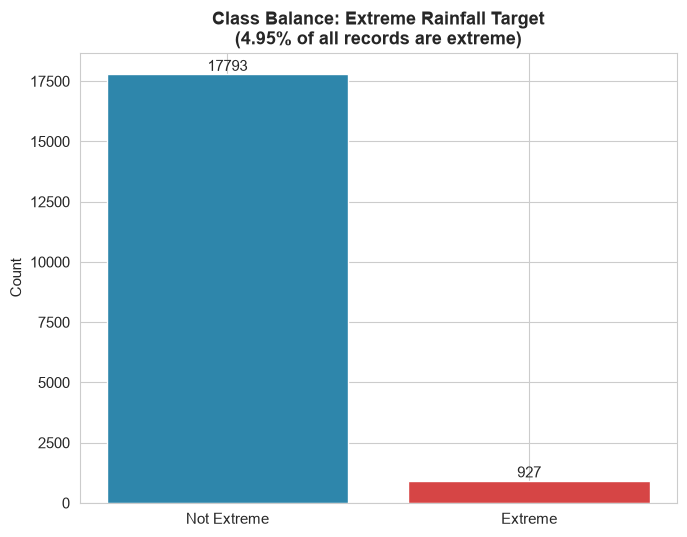


Saved: Imbalanced Class.png


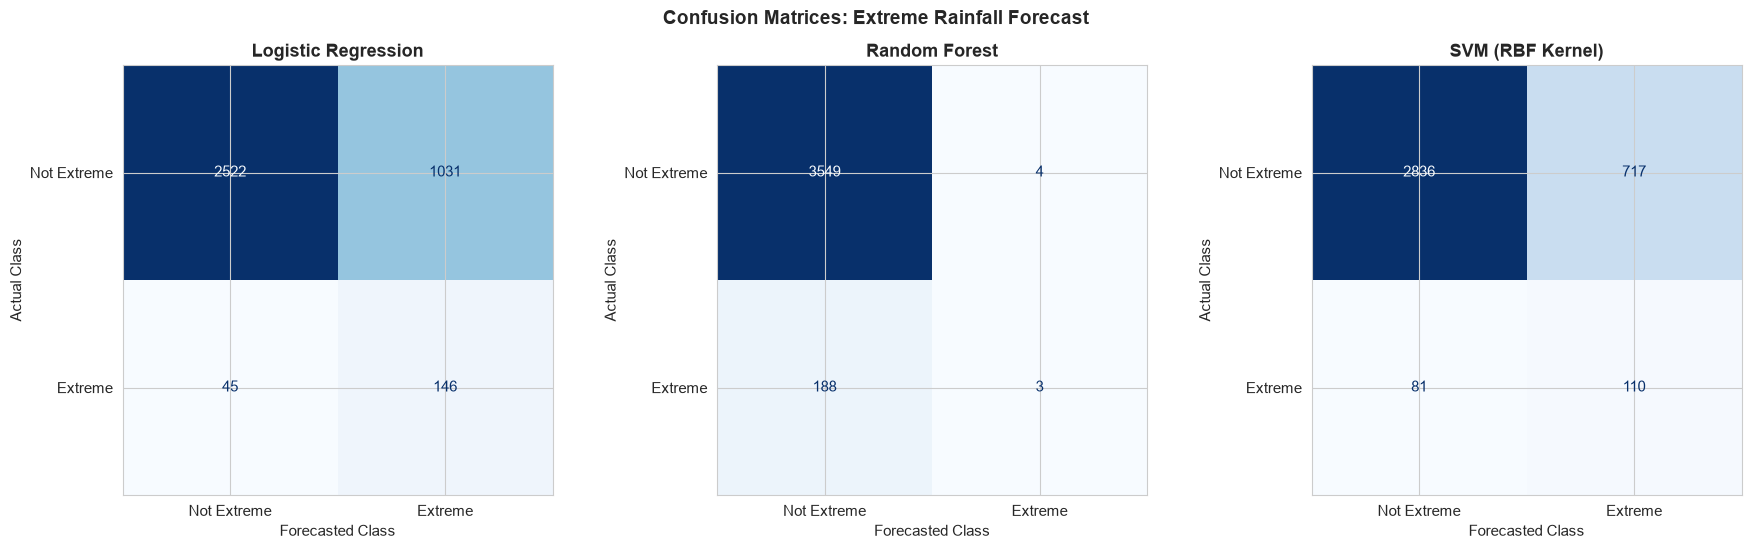

Saved: Confusion Matrices.png


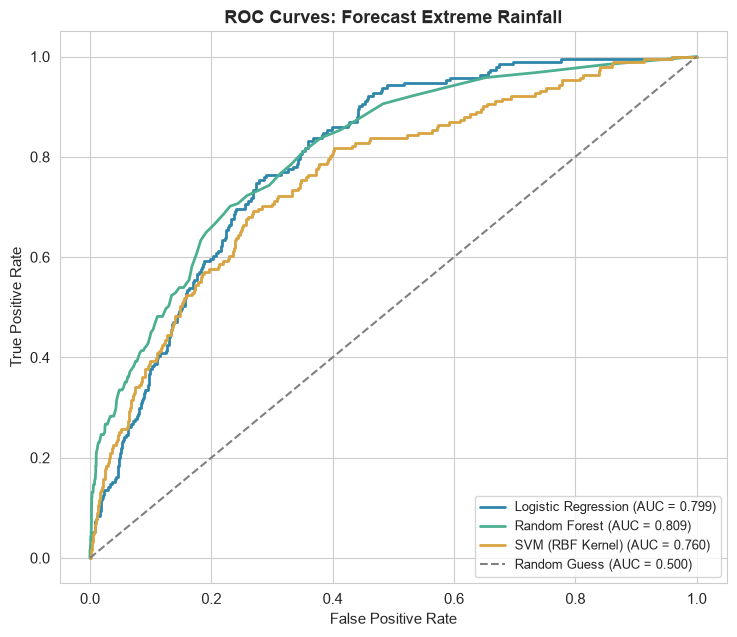

Saved: ROC Curves.png


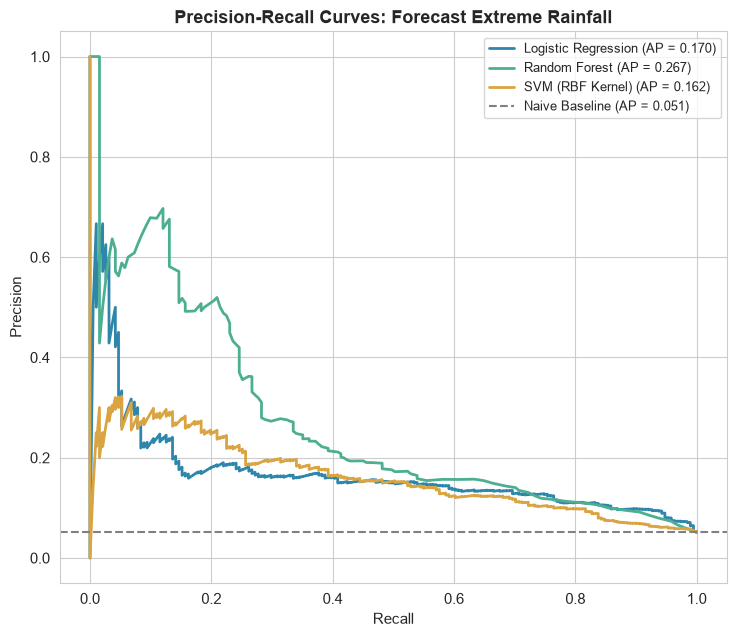

Saved: Precision Recall Curve.png


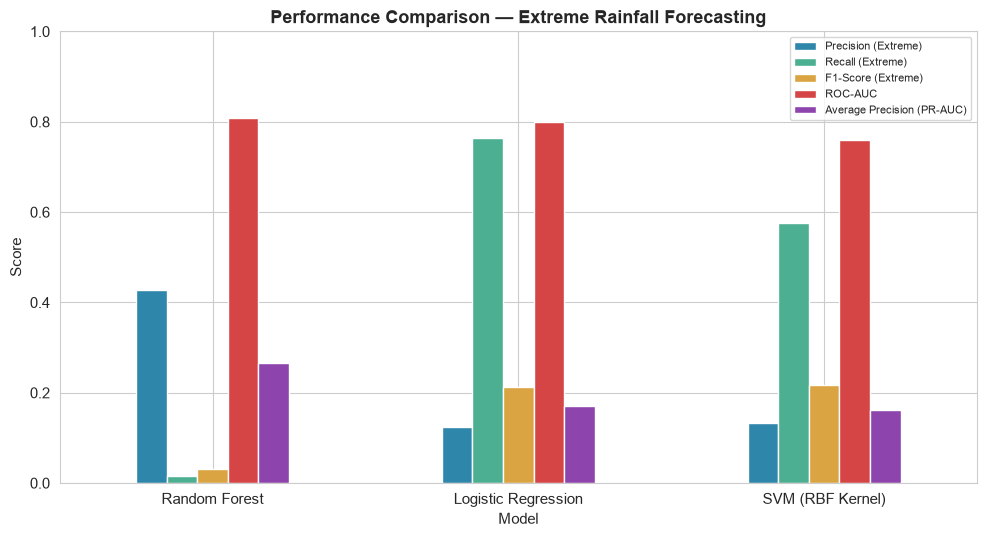

Saved: Performance Comparison.png


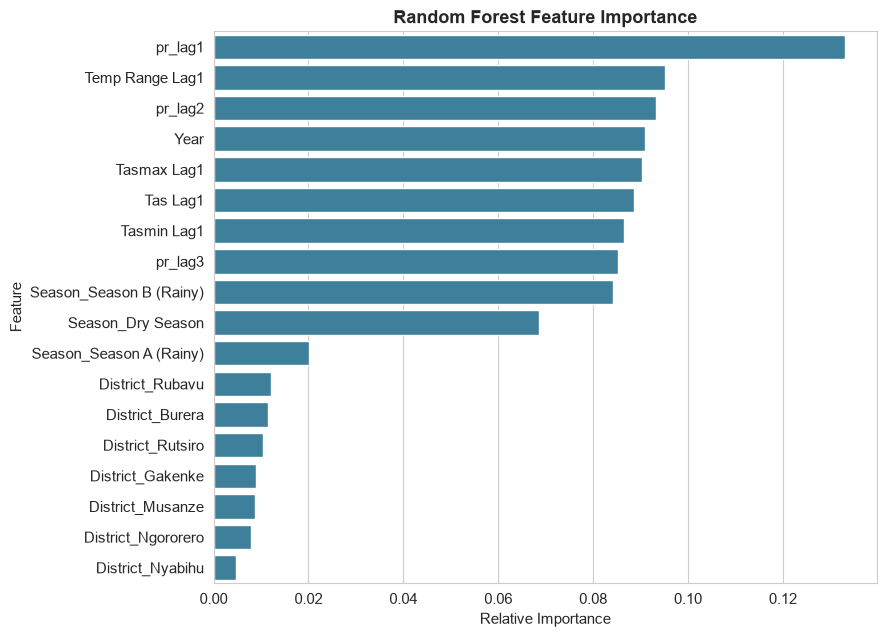

Saved: Feature Importance.png

EXTREME RAINFALL MODELING SUCCESSFULLY COMPLETE
Best model by Average Precision (PR-AUC): Random Forest (0.2669)
Naive baseline Average Precision: 0.0510


In [2]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report,
                              confusion_matrix, roc_curve, roc_auc_score,
                              precision_recall_curve, average_precision_score,
                              ConfusionMatrixDisplay)

RANDOM_STATE = 42

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
})

MODEL_COLORS = {"Logistic Regression": "#2E86AB",
                 "Random Forest": "#4CAF91",
                 "SVM (RBF Kernel)": "#D9A441"}

df = pd.read_csv("Processed Data.csv", parse_dates=["date"])
df["grid_cell_id"] = df["Latitude"].astype(str) + "_" + df["Longitude"].astype(str)
df = df.sort_values(["grid_cell_id", "Year", "Month"]).reset_index(drop=True)

print("=" * 140)
print(f"Loaded {df.shape[0]} rows. Extreme events: "
      f"{df['is_extreme_rainfall'].sum()} ({df['is_extreme_rainfall'].mean()*100:.2f}%)")
print("=" * 140)

# ==========================================================================
# STEP 1: BUILDING LAGGED TEMPERATURE FEATURES (Safe for Forecasting/Predictions)
# ==========================================================================
print("\nSTEP 1: LAGGED TEMPERATURE FEATURES - SAFE For Forecasting/Predictions")

temp_src_cols = ["tas", "tasmin", "tasmax", "temp_range"]
temp_lag_names = ["Tas Lag1", "Tasmin Lag1", "Tasmax Lag1", "Temp Range Lag1"]
for src, new in zip(temp_src_cols, temp_lag_names):
    df[new] = df.groupby("grid_cell_id")[src].shift(1)


for col in temp_lag_names:
    df[col] = df.groupby("grid_cell_id")[col].transform(lambda s: s.fillna(s.mean()))

print(f"Created: {temp_lag_names} (Grid Cell Mean Filled for NaN Records)")

# One-hot encoding Season (District_* dummies )
season_dummies = pd.get_dummies(df["Season"], prefix="Season", dtype=int)
df = pd.concat([df, season_dummies], axis=1)

district_cols = [c for c in df.columns if c.startswith("District_")]
FEATURE_COLS = (
    ["pr_lag1", "pr_lag2", "pr_lag3"] + temp_lag_names
    + district_cols + list(season_dummies.columns) + ["Year"]
)
print(f"\nFeatures Added ({len(FEATURE_COLS)}): {FEATURE_COLS}")

preview = df[FEATURE_COLS + ["is_extreme_rainfall"]].head(10)
preview.to_csv("Lagged Features Preview.csv", index=False)

X = df[FEATURE_COLS].copy()
y = df["is_extreme_rainfall"].copy()

# ==========================================================================
# STEP 2: TRAIN / TEST SPLIT - Chronological
# ==========================================================================
print("\n" + "=" * 140)
print("STEP 2: TRAIN / TEST SPLIT")
print("=" * 140)

# Sort observations chronologically
df = df.sort_values(by="date").reset_index(drop=True)

# Defining the chronological split 
split_index = int(len(df) * 0.80)

# Splitting features and target chronologically
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Class Distribution Summary
split_rows = []

for label, series in [("Train", y_train), ("Test", y_test)]:
    for cls, cls_label in [(0, "Not Extreme"), (1, "Extreme")]:
        n = (series == cls).sum()

        split_rows.append({
            "Split": label,
            "Class": cls_label,
            "N": int(n),
            "Percent of Split (%)": round(n / len(series) * 100, 2)
        })

split_summary = pd.DataFrame(split_rows)

print(split_summary.to_string(index=False))

split_summary.to_csv("Train Test Split Summary.csv", index=False)

print(f"\nTraining Observations: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Test Observations    : {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")

print(f"\nTraining Time: {df['date'].iloc[0]} - {df['date'].iloc[split_index-1]}")
print(f"Testing Time : {df['date'].iloc[split_index]} - {df['date'].iloc[-1]}")

# ==========================================================================
# STEP 3: TRAIN MODELS (class_weight='balanced')
# ==========================================================================
print("\n" + "=" * 140)
print("STEP 3: TRAINING MODELS")
print("=" * 140)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced", n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "SVM (RBF Kernel)": SVC(
        class_weight="balanced", kernel="rbf", C=1.0, gamma="scale",
        probability=True, random_state=RANDOM_STATE
    ),
}

predictions, probabilities = {}, {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)
    probabilities[name] = model.predict_proba(X_test_scaled)[:, 1]
    print(f"-> {name} trained.")

# ==========================================================================
# STEP 4: MODEL PERFORMANCE COMPARISON 
# ==========================================================================
print("\n" + "=" * 140)
print("MODEL PERFORMANCE")
print("=" * 140)

perf_rows = []
for name, y_pred in predictions.items():
    y_prob = probabilities[name]
    perf_rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision (Extreme)": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall (Extreme)": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1-Score (Extreme)": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4),
        "Average Precision (PR-AUC)": round(average_precision_score(y_test, y_prob), 4),
    })
performance_summary = pd.DataFrame(perf_rows).sort_values(
    "Average Precision (PR-AUC)", ascending=False
)
print(performance_summary.to_string(index=False))
performance_summary.to_csv("Model Performance Comparison.csv", index=False)

naive_precision = y_test.mean()
print(f"\nNaive baseline for Average Precision: "
      f"{naive_precision:.4f} -- Percentage of Positives in the test set, "
      f"i.e. the floor a least important model would score. Compare "
      f"every model's PR-AUC against this, not against 1.0.")
print(f"Naive baseline accuracy--always predict 'Not Extreme': "
      f"{1 - naive_precision:.4f} -- highly deceptive; ignore accuracy alone "
      f"for this imbalanced task.")

# ==========================================================================
# STEP 5: PER-CLASS CLASSIFICATION REPORT
# ==========================================================================
report_rows = []
for name, y_pred in predictions.items():
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    for cls, cls_label in [("0", "Not Extreme"), ("1", "Extreme")]:
        r = report[cls]
        report_rows.append({
            "Model": name, "Class": cls_label,
            "Precision": round(r["precision"], 3),
            "Recall": round(r["recall"], 3),
            "F1-Score": round(r["f1-score"], 3),
            "Support": int(r["support"]),
        })
classification_long = pd.DataFrame(report_rows)
print("\n" + classification_long.to_string(index=False))
classification_long.to_csv("Extended Classification Report.csv", index=False)

# ==========================================================================
# STEP 6: RANDOM FOREST FEATURE IMPORTANCE
# ==========================================================================
rf_model = models["Random Forest"]
importance_df = pd.DataFrame({
    "Feature": FEATURE_COLS,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)
print("\n" + "=" * 140)
print("TABLE: RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 140)
print(importance_df.to_string(index=False))
importance_df.to_csv("Random Forest Feature Importance.csv", index=False)

# ==========================================================================
# FIGURES
# ==========================================================================

# Figure A: Class imbalance
fig, ax = plt.subplots(figsize=(7, 5.5))
counts = df["is_extreme_rainfall"].value_counts().sort_index()
bars = ax.bar(["Not Extreme", "Extreme"], counts.values, color=["#2E86AB", "#D64545"])
ax.bar_label(bars)
ax.set_title(f"Class Balance: Extreme Rainfall Target\n"
             f"({df['is_extreme_rainfall'].mean()*100:.2f}% of all records are extreme)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig("Imbalanced Class.png")
display(fig)
plt.close()
print("\nSaved: Imbalanced Class.png")

# Figure B: Confusion matrices 

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=["Not Extreme", "Extreme"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.set_xlabel("Forecasted Class")
    ax.set_ylabel("Actual Class")
fig.suptitle("Confusion Matrices: Extreme Rainfall Forecast",
             fontweight="bold", fontsize=14)
plt.tight_layout()
plt.savefig("Confusion Matrices.png")
display(fig)
plt.close()
print("Saved: Confusion Matrices.png")

# Figure C: ROC curves (all three models overlaid)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})",
            color=MODEL_COLORS[name], linewidth=2)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess (AUC = 0.500)")
ax.set_title("ROC Curves: Forecast Extreme Rainfall")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("ROC Curves.png")
display(fig)
plt.close()
print("Saved: ROC Curves.png")

# Figure D: Precision-Recall curves 
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for name, y_prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    ax.plot(recall, precision, label=f"{name} (AP = {ap:.3f})",
            color=MODEL_COLORS[name], linewidth=2)
ax.axhline(naive_precision, linestyle="--", color="gray",
           label=f"Naive Baseline (AP = {naive_precision:.3f})")
ax.set_title("Precision-Recall Curves: Forecast Extreme Rainfall")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig("Precision Recall Curve.png")
display(fig)
plt.close()
print("Saved: Precision Recall Curve.png")

# Figure E: Model performance comparison
fig, ax = plt.subplots(figsize=(10, 5.5))
metrics_to_plot = ["Precision (Extreme)", "Recall (Extreme)", "F1-Score (Extreme)",
                    "ROC-AUC", "Average Precision (PR-AUC)"]
plot_df = performance_summary.set_index("Model")[metrics_to_plot]
plot_df.plot(kind="bar", ax=ax, color=["#2E86AB", "#4CAF91", "#D9A441", "#D64545", "#8E44AD"])
ax.set_title("Performance Comparison — Extreme Rainfall Forecasting")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="upper right", fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("Performance Comparison.png")
display(fig)
plt.close()
print("Saved: Performance Comparison.png")

# Figure F: Random Forest feature importance
fig, ax = plt.subplots(figsize=(9, 6.5))
sns.barplot(data=importance_df, x="Importance", y="Feature", color="#2E86AB", ax=ax)
ax.set_title("Random Forest Feature Importance")
ax.set_xlabel("Relative Importance")
plt.tight_layout()
plt.savefig("Feature Importance.png")
display(fig)
plt.close()
print("Saved: Feature Importance.png")

print("\n" + "=" * 140)
print("EXTREME RAINFALL MODELING SUCCESSFULLY COMPLETE")
best_model = performance_summary.iloc[0]
print(f"Best model by Average Precision (PR-AUC): {best_model['Model']} "
      f"({best_model['Average Precision (PR-AUC)']})")
print(f"Naive baseline Average Precision: {naive_precision:.4f}")
print("=" * 140)


In [ ]:
`